# LFTSAD: Lightweight and Fast Time-Series Anomaly Detection

**Paper implemented:** L. Chen, J. Tang, Y. Zou, X. Liu, X. Xie and G. Deng, *"Lightweight and Fast Time-Series Anomaly Detection via Point-Level and Sequence-Level Reconstruction Discrepancy,"* IEEE Transactions on Neural Networks and Learning Systems, vol. 36, no. 9, pp. 17295–17309, Sept. 2025. DOI: [10.1109/TNNLS.2025.3565807](https://doi.org/10.1109/TNNLS.2025.3565807)

**M.Tech (Artificial Intelligence) · Department of Computer Science & Engineering · Delhi Technological University**

| | |
|---|---|
| **Submitted by** | Adarsh kumar (26/AFI/024) Romit Chakma (26/AFI/029)|
| **Course** | Python with Machine Learning |
| **Submitted to** | Mr. Lavendra Gautam |

## About this notebook

In this notebook we implement LFTSAD from scratch in PyTorch and evaluate it on **5 of the 8 multivariate benchmarks** used in the paper: **MSL, SMAP, SMD, PSM and GECCO**.

* To keep the whole notebook within **~10 minutes on Google Colab**, every dataset is reduced to **~10% of its original size** (Section 3 explains how we did this without destroying the time-series structure).
* The model follows the equations of the paper (Sections IV-B to IV-D). Hyper-parameters that are not given in the paper are taken from the authors' official repository ([infogroup502/LFTSAD](https://github.com/infogroup502/LFTSAD)).
* We also reproduce small versions of the paper's ablation study (RQ-3), α sensitivity (RQ-4) and timeliness analysis (RQ-2).

**How to run:** `Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all`. All the libraries used are pre-installed on Colab. The notebook also runs on a CPU runtime with identical settings (around 5–6 minutes instead of 1–2).

### Contents
1. Setup
2. Configuration
3. Datasets (download + 10% reduction)
4. The LFTSAD model
5. Training and anomaly scoring
6. Evaluation metrics
7. Running LFTSAD on all datasets
8. Results vs. the paper (RQ-1)
9. Ablation: point-level vs sequence-level (RQ-3)
10. Sensitivity to α (RQ-4)
11. Timeliness and model size (RQ-2)
12. Visualising detections
13. Observations and conclusion

## 1. Setup

In [ ]:
import os, sys, ast, time, random, warnings, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, RandomSampler

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, f1_score

warnings.filterwarnings('ignore')
pd.set_option('display.precision', 4)

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch :', torch.__version__)
print('Device  :', device, '-', torch.cuda.get_device_name(0) if device.type == 'cuda' else 'no GPU found (will run slower)')
NOTEBOOK_START = time.time()

PyTorch : 2.14.1+cu130
Device  : cuda - Tesla T4


## 2. Configuration

| Parameter | Value | Source |
|---|---|---|
| Window length WIN | 100 | official code (`--win_size 100`) |
| Point-level grid P1 × P2 | 10 × 10 | official code (`--patch_size [10]`) |
| Sequence-level grid S1 × S2 × S3 | 5 × 4 × 5 | official code (`--patch_seq [5]`, `--seq_size 5`) |
| Hidden neurons d | 128 | official code (`--d_model 128`) |
| Batch size | 128 | paper, Sec. V-F |
| Learning rate | 1e-4, halved every epoch | official code |
| Epochs | 1 | official code (`--num_epochs 1`) |
| α (weight of point-level score) | 0.8 | paper Sec. V-H: stable range for multivariate data is [0.7, 1.0] |
| Anomaly ratio for threshold (%) | 1.0 (0.5 for SMD) | standard values used by Anomaly Transformer / DCdetector style code |
| Dropout | 0 | official code uses none (the paper mentions dropout, we keep it optional) |

**Training budget:** in one epoch the official code visits every stride-1 window of the training set. We sample random windows instead and cap the epoch at **100 iterations** on both GPU and CPU, so results do not depend on the device. With 10% data this is about one full pass for MSL, SMAP and PSM. For SMD (~590 possible iterations) we tested a full pass and it made the point-level score *worse* (see Observation 6), so the cap also avoids over-training.

In [ ]:
CFG = {
    'win_size'   : 100,
    'P1': 10, 'P2': 10,             # point-level   : P1 x P2      = WIN
    'S1': 5,  'S2': 4,  'S3': 5,    # sequence-level: S1 x S2 x S3 = WIN
    'd_model'    : 128,             # hidden neurons d of every two-layer MLP
    'dropout'    : 0.0,
    'batch_size' : 128,
    'lr'         : 1e-4,
    'num_epochs' : 1,
    'max_iters_per_epoch': 100,     # same on GPU and CPU (see the note above)
    'alpha'      : 0.8,             # Score = alpha * Score_P + (1 - alpha) * Score_S   (eq. 13)
}

# anomaly ratio (%) used to pick the threshold, per dataset
ANOMALY_RATIO = {'MSL': 1.0, 'SMAP': 1.0, 'SMD': 0.5, 'PSM': 1.0, 'GECCO': 1.0}

DATASETS = ['MSL', 'SMAP', 'SMD', 'PSM', 'GECCO']
DATA_DIR = './data'
DATA_FRACTION = 0.10     # keep ~10% of every dataset
SEED = 42

## 3. Datasets

| Dataset | Domain | Variables | Full train / test (Table I) | Source we download from |
|---|---|---|---|---|
| MSL | Mars Science Laboratory rover telemetry | 55 | 58,317 / 73,729 | NASA telemanom data (mirrored in the TranAD repo) |
| SMAP | Soil Moisture Active Passive satellite | 25 | 135,183 / 427,617 | same as MSL |
| SMD | 28 server machines of a large internet company | 38 | 708,405 / 708,420 | OmniAnomaly repo |
| PSM | eBay pooled server metrics | 25 | 132,480 / 87,840 | eBay RANSynCoders repo |
| GECCO | drinking water quality (GECCO 2018 challenge) | 9 | 69,260 / 69,261 | Zenodo |

SWaT and WADI need a request form from iTrust (SUTD), SWAN is not easily downloadable, and the univariate datasets come as one ~GB archive (TSB-UAD), so we leave these out to stay within the time budget.

### How we reduce each dataset to ~10%

We cannot just sample random rows, since that destroys the temporal order the model depends on. Instead:

* **MSL, SMAP and SMD** are really *many separate series concatenated* (telemetry channels / server machines). We keep a **subset of complete channels / machines** covering ~10% of the rows. For MSL/SMAP we try 50 random subsets and keep the one whose anomaly ratio is closest to the full dataset, so the reduced version stays representative. Only the selected files are downloaded.
* **PSM and GECCO** are single long recordings. We keep the **first 10% of the train set** and **one contiguous 10% slice of the test set**, chosen so that its anomaly ratio is close to that of the full test set (a random slice could contain no anomalies at all).

We use the standard preprocessing for every dataset: MSL/SMAP channels are concatenated with channel P-2 removed, label ranges come from `labeled_anomalies.csv`, and GECCO is split into first half = train and second half = test.

In [ ]:
def download(url, path, retries=3):
    """Download a file (skipped if it already exists)."""
    if os.path.exists(path) and os.path.getsize(path) > 0:
        return path
    os.makedirs(os.path.dirname(path), exist_ok=True)
    for attempt in range(retries):
        try:
            urllib.request.urlretrieve(url, path)
            return path
        except Exception as e:
            print(f'   download failed ({attempt + 1}/{retries}): {e}')
            time.sleep(2)
    raise RuntimeError(f'Could not download {url}')


def pick_test_slice(test, labels, frac):
    """Return one contiguous slice (frac of the length) of the test set whose anomaly
    ratio is closest to the anomaly ratio of the whole test set."""
    n = int(len(test) * frac)
    full_ratio = labels.mean()
    csum = np.concatenate([[0], np.cumsum(labels)])
    best_start, best_gap = 0, 1e9
    for start in range(0, len(test) - n + 1, max(1, n // 20)):
        ratio = (csum[start + n] - csum[start]) / n
        if ratio > 0 and abs(ratio - full_ratio) < best_gap:
            best_start, best_gap = start, abs(ratio - full_ratio)
    return test[best_start:best_start + n], labels[best_start:best_start + n]


def save_dataset(name, train, test, labels):
    out = os.path.join(DATA_DIR, name)
    os.makedirs(out, exist_ok=True)
    np.save(f'{out}/train.npy', train.astype(np.float32))
    np.save(f'{out}/test.npy', test.astype(np.float32))
    np.save(f'{out}/test_label.npy', labels.astype(np.int64))

In [ ]:
# ---------------- MSL and SMAP (NASA) ----------------
NASA_URL = 'https://raw.githubusercontent.com/imperial-qore/TranAD/main/data/SMAP_MSL'

def prepare_nasa(spacecraft):
    raw = os.path.join(DATA_DIR, 'raw_nasa')
    meta = pd.read_csv(download(f'{NASA_URL}/labeled_anomalies.csv', f'{raw}/labeled_anomalies.csv'))
    meta = meta[(meta.spacecraft == spacecraft) & (meta.chan_id != 'P-2')]   # P-2 is dropped in the standard version
    meta = meta.sort_values('chan_id').reset_index(drop=True)

    # anomalous points per channel can be counted from the csv itself (no download needed)
    n_anom = meta.anomaly_sequences.apply(lambda s: sum(e - st + 1 for st, e in ast.literal_eval(s))).values
    total_test = meta.num_values.sum()
    full_ratio = n_anom.sum() / total_test

    # try 50 random channel subsets (~10% of the test length each), keep the most representative one
    best, best_gap = None, 1e9
    for trial in range(50):
        order = np.random.RandomState(SEED + trial).permutation(len(meta))
        chosen, count = [], 0
        for i in order:
            chosen.append(i)
            count += meta.num_values[i]
            if count >= DATA_FRACTION * total_test:
                break
        gap = abs(n_anom[chosen].sum() / count - full_ratio)
        if gap < best_gap:
            best, best_gap = sorted(chosen), gap

    trains, tests, labels = [], [], []
    for i in best:
        ch = meta.chan_id[i]
        tr = np.load(download(f'{NASA_URL}/train/{ch}.npy', f'{raw}/train/{ch}.npy'))
        te = np.load(download(f'{NASA_URL}/test/{ch}.npy', f'{raw}/test/{ch}.npy'))
        lab = np.zeros(len(te), dtype=np.int64)
        for s, e in ast.literal_eval(meta.anomaly_sequences[i]):
            lab[s:e + 1] = 1                      # ranges in the csv are inclusive
        trains.append(tr); tests.append(te); labels.append(lab)
    print(f'   channels used: {[meta.chan_id[i] for i in best]}')
    return np.concatenate(trains), np.concatenate(tests), np.concatenate(labels)


# ---------------- SMD ----------------
SMD_URL = 'https://raw.githubusercontent.com/NetManAIOps/OmniAnomaly/master/ServerMachineDataset'
SMD_MACHINES = ([f'machine-1-{i}' for i in range(1, 9)] + [f'machine-2-{i}' for i in range(1, 10)] +
                [f'machine-3-{i}' for i in range(1, 12)])
SMD_TOTAL_TRAIN = 708405                          # all 28 machines (Table I)

def prepare_smd():
    raw = os.path.join(DATA_DIR, 'raw_smd')
    order = np.random.RandomState(SEED).permutation(len(SMD_MACHINES))
    trains, tests, labels, used, count = [], [], [], [], 0
    for i in order:                               # add whole machines until we have ~10% of the rows
        m = SMD_MACHINES[i]
        tr = np.loadtxt(download(f'{SMD_URL}/train/{m}.txt', f'{raw}/train/{m}.txt'), delimiter=',')
        te = np.loadtxt(download(f'{SMD_URL}/test/{m}.txt', f'{raw}/test/{m}.txt'), delimiter=',')
        lab = np.loadtxt(download(f'{SMD_URL}/test_label/{m}.txt', f'{raw}/test_label/{m}.txt'), delimiter=',')
        trains.append(tr); tests.append(te); labels.append(lab.astype(np.int64)); used.append(m)
        count += len(tr)
        if count >= DATA_FRACTION * SMD_TOTAL_TRAIN:
            break
    print(f'   machines used: {used}')
    return np.concatenate(trains), np.concatenate(tests), np.concatenate(labels)


# ---------------- PSM ----------------
PSM_URL = 'https://raw.githubusercontent.com/eBay/RANSynCoders/main/data'

def prepare_psm():
    raw = os.path.join(DATA_DIR, 'raw_psm')
    train = pd.read_csv(download(f'{PSM_URL}/train.csv', f'{raw}/train.csv')).values[:, 1:]   # col 0 = timestamp
    test = pd.read_csv(download(f'{PSM_URL}/test.csv', f'{raw}/test.csv')).values[:, 1:]
    labels = pd.read_csv(download(f'{PSM_URL}/test_label.csv', f'{raw}/test_label.csv')).values[:, 1].astype(np.int64)
    train, test = np.nan_to_num(train), np.nan_to_num(test)   # PSM has a few missing values
    train = train[:int(len(train) * DATA_FRACTION)]
    test, labels = pick_test_slice(test, labels, DATA_FRACTION)
    return train, test, labels


# ---------------- GECCO ----------------
GECCO_URL = 'https://zenodo.org/records/3884398/files/1_gecco2018_water_quality.csv?download=1'

def prepare_gecco():
    raw = os.path.join(DATA_DIR, 'raw_gecco')
    df = pd.read_csv(download(GECCO_URL, f'{raw}/gecco2018.csv'))
    labels = df.pop('EVENT').astype(str).str.lower().isin(['true', '1', '1.0']).astype(np.int64).values
    df = df.drop(columns=[c for c in df.columns if c.lower().startswith('unnamed')])   # row-index column
    df = df.select_dtypes(include=[np.number])                  # drops the Time column
    values = df.ffill().bfill().values                          # a few sensor readings are missing
    print(f'   GECCO sensors: {list(df.columns)}')
    half = len(values) // 2                                     # first half = train, second half = test
    train, test, test_labels = values[:half], values[half:], labels[half:]
    train = train[:int(len(train) * DATA_FRACTION)]
    test, test_labels = pick_test_slice(test, test_labels, DATA_FRACTION)
    return train, test, test_labels


PREPARE_FUNCS = {'MSL': lambda: prepare_nasa('MSL'), 'SMAP': lambda: prepare_nasa('SMAP'),
                 'SMD': prepare_smd, 'PSM': prepare_psm, 'GECCO': prepare_gecco}

In [ ]:
t0 = time.time()
available, summary = [], []
for name in DATASETS:
    print(f'Preparing {name} ...')
    try:
        train, test, labels = PREPARE_FUNCS[name]()
    except Exception as e:
        # if one source is down we simply skip that dataset instead of crashing the notebook
        print(f'   !! skipping {name}: {e}')
        continue
    save_dataset(name, train, test, labels)
    available.append(name)
    summary.append([name, train.shape[1], len(train), len(test), 100 * labels.mean()])

DATASETS = available
summary = pd.DataFrame(summary, columns=['Dataset', 'Variables', 'Train', 'Test', 'Anomaly %'])
print(f'\nData ready in {time.time() - t0:.1f}s')
summary

Preparing MSL ...
   channels used: ['F-8', 'P-11', 'T-12']
Preparing SMAP ...
   channels used: ['A-2', 'A-4', 'A-8', 'B-1', 'P-7', 'S-1']
Preparing SMD ...
   machines used: ['machine-2-2', 'machine-3-9', 'machine-2-1']
Preparing PSM ...
Preparing GECCO ...
   GECCO sensors: ['Tp', 'Cl', 'pH', 'Redox', 'Leit', 'Trueb', 'Cl_2', 'Fm', 'Fm_2']

Data ready in 27.2s


,Dataset,Variables,Train,Test,Anomaly %
0,MSL,55,8456,8452,10.4827
1,SMAP,25,14206,47815,12.9625
2,SMD,38,76105,76107,5.6578
3,PSM,25,13248,8784,27.5842
4,GECCO,9,6978,6978,0.9888


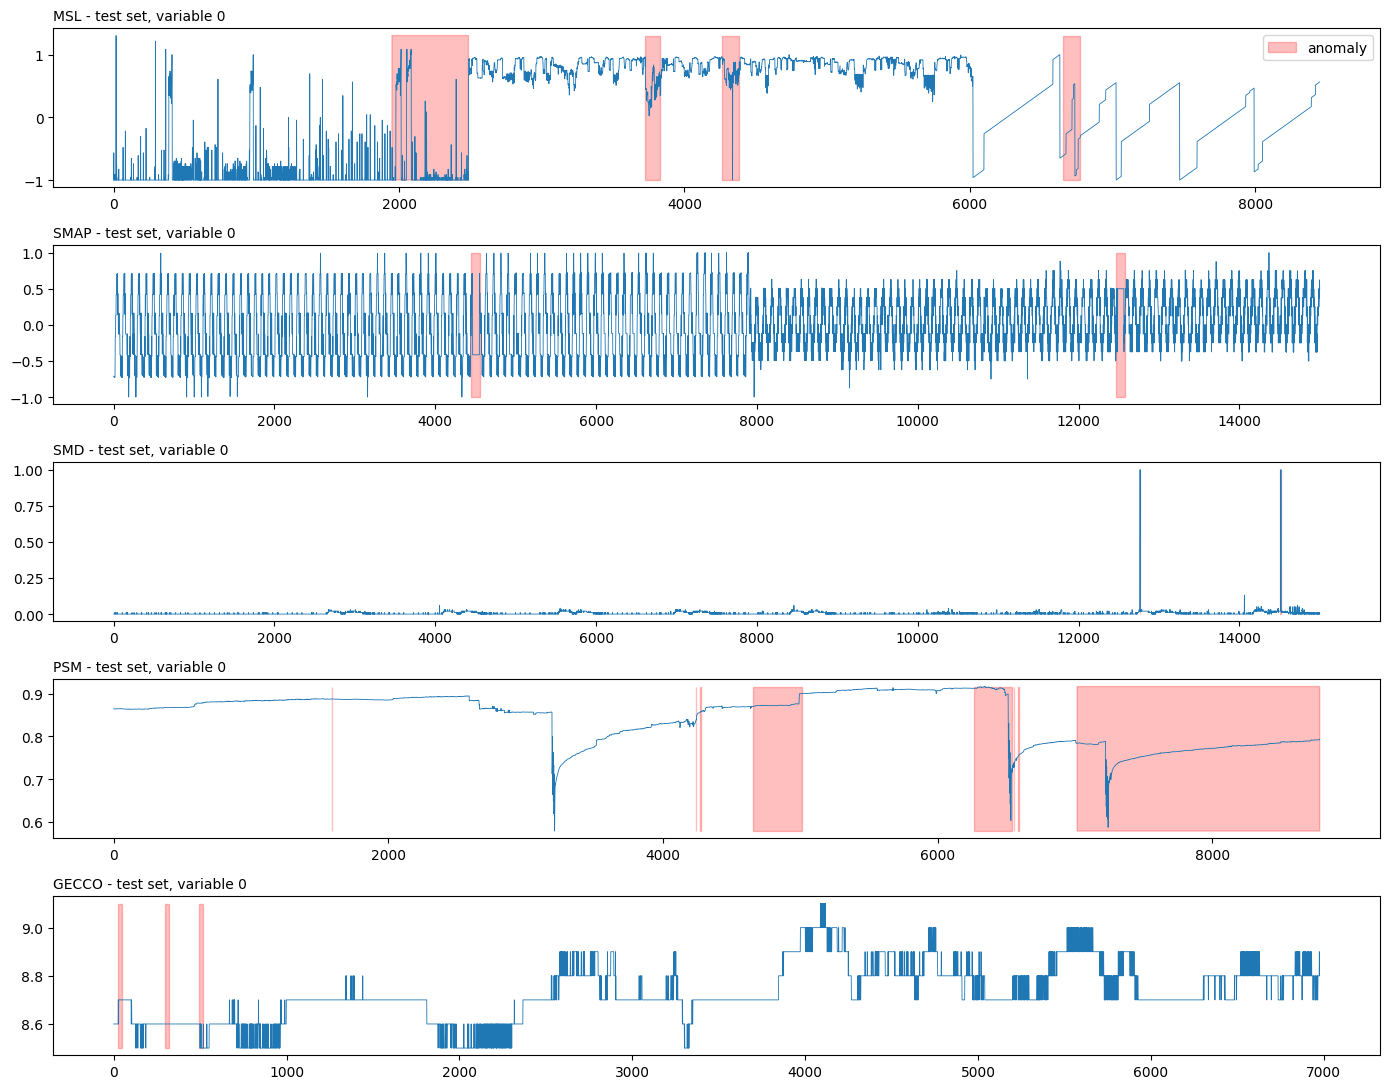

In [ ]:
# quick look at the data: first variable of every test set, true anomalies in red
fig, axes = plt.subplots(len(DATASETS), 1, figsize=(14, 2.2 * len(DATASETS)))
axes = np.atleast_1d(axes)
for ax, name in zip(axes, DATASETS):
    test = np.load(f'{DATA_DIR}/{name}/test.npy')
    lab = np.load(f'{DATA_DIR}/{name}/test_label.npy')
    n = min(len(test), 15000)
    ax.plot(test[:n, 0], lw=0.6, color='tab:blue')
    ax.fill_between(np.arange(n), test[:n, 0].min(), test[:n, 0].max(),
                    where=lab[:n] == 1, color='red', alpha=0.25, label='anomaly')
    ax.set_title(f'{name} - test set, variable 0', fontsize=10, loc='left')
axes[0].legend(loc='upper right')
plt.tight_layout()
plt.show()

## 4. The LFTSAD model

LFTSAD uses only **four two-layer MLPs**, grouped into two parallel branches (Fig. 4 of the paper). Every variable of a multivariate series is processed **independently with the same MLPs**, so the window of shape (B, WIN, M) is reshaped to (B·M, WIN).

**Core idea (association discrepancy without attention).** A normal timestamp is strongly associated with both its *local* neighbours (adjacent points) and its *global* neighbours (points one period away). An anomaly is mostly associated with its local neighbours only. So we reconstruct each timestamp **twice**, once from local and once from global neighbours. If the two reconstructions agree, the point is normal. If they disagree, it is anomalous.

### 4.1 Point-level branch (Sec. IV-B)
The window is reshaped into a $P_1 \times P_2$ matrix ($P_1$ segments of $P_2$ consecutive points). For the timestamp at row $i$, column $j$:
* local neighbours $LP(x_t)$ = the other $P_2-1$ points of row $i$ → $\tilde{x}_t = \mathrm{ReLU}(LP(x_t) W_1^1) W_2^1$  (eq. 3–4)
* global neighbours $GP(x_t)$ = the other $P_1-1$ points of column $j$ → $\bar{x}_t = \mathrm{ReLU}(GP(x_t) W_1^2) W_2^2$  (eq. 5–6)
* loss: $\mathrm{Loss}_P = \frac{1}{M}\sum_m \frac{1}{WIN}\sum_t (\tilde{x}_t^m - \bar{x}_t^m)^2$  (eq. 7)

### 4.2 Sequence-level branch (Sec. IV-C)
This branch handles *implicit* outliers, which look normal point-by-point but not as a sub-sequence. The window becomes an $S_1 \times S_2$ matrix of sub-sequences of length $S_3$. Each timestamp is replaced by the sub-sequence that contains it (its "substitute"):
* local neighbours = the other $S_2-1$ sub-sequences in its row (input $(S_2-1)\cdot S_3$, output $S_3$)  (eq. 8–9)
* global neighbours = the other $S_1-1$ sub-sequences in its column (input $(S_1-1)\cdot S_3$, output $S_3$)  (eq. 10–11)
* loss $\mathrm{Loss}_S$ is the MSE between the two reconstructed sub-sequences (eq. 12)

### 4.3 Anomaly score (Sec. IV-D)
$$\mathrm{Score}(x_t) = \alpha \cdot \mathrm{Score}^P(x_t) + (1-\alpha)\cdot \mathrm{Score}^S(x_t)$$
where each term is the squared reconstruction discrepancy averaged over the $M$ variables (eq. 13).

**Implementation note:** instead of looping over timestamps (as in the official code), we build all neighbour sets with one index gather, using a small "leave-one-out" index matrix. The whole window is then processed in one batched matrix multiplication.

In [ ]:
class TwoLayerMLP(nn.Module):
    """FC -> ReLU -> (Dropout) -> FC. This is the only building block of LFTSAD."""
    def __init__(self, in_dim, hidden_dim, out_dim, dropout=0.0):
        super().__init__()
        self.fc1 = nn.Linear(in_dim, hidden_dim)    # first FCL
        self.fc2 = nn.Linear(hidden_dim, out_dim)   # second FCL
        self.act = nn.ReLU()
        self.drop = nn.Dropout(dropout) if dropout > 0 else nn.Identity()

    def forward(self, x):
        return self.fc2(self.drop(self.act(self.fc1(x))))


def leave_one_out_index(n):
    """(n, n-1) index matrix, row k = every index except k.   e.g. n=3 -> [[1,2],[0,2],[0,1]]"""
    return torch.tensor([[j for j in range(n) if j != k] for k in range(n)], dtype=torch.long)

print(leave_one_out_index(4))

tensor([[1, 2, 3],
        [0, 2, 3],
        [0, 1, 3],
        [0, 1, 2]])


In [ ]:
class PointLevelBranch(nn.Module):
    """Point-level reconstruction discrepancy learning (Sec. IV-B, Fig. 4a / 5a)."""
    def __init__(self, P1, P2, d_model, dropout):
        super().__init__()
        self.P1, self.P2 = P1, P2
        self.local_mlp = TwoLayerMLP(P2 - 1, d_model, 1, dropout)    # eq. (3)-(4)
        self.global_mlp = TwoLayerMLP(P1 - 1, d_model, 1, dropout)   # eq. (5)-(6)
        self.register_buffer('row_idx', leave_one_out_index(P2))
        self.register_buffer('col_idx', leave_one_out_index(P1))

    def forward(self, x):                                   # x: (N, WIN), N = batch * variables
        N = x.shape[0]
        G = x.reshape(N, self.P1, self.P2)                  # the 2-D sampling matrix

        local_nb = G[:, :, self.row_idx]                                    # (N, P1, P2, P2-1)
        global_nb = G.transpose(1, 2)[:, :, self.col_idx].transpose(1, 2)   # (N, P1, P2, P1-1)

        x_local = self.local_mlp(local_nb).reshape(N, -1)    # (N, WIN)   x tilde
        x_global = self.global_mlp(global_nb).reshape(N, -1) # (N, WIN)   x bar
        return x_local, x_global


class SequenceLevelBranch(nn.Module):
    """Sequence-level reconstruction discrepancy learning (Sec. IV-C, Fig. 4b / 5b)."""
    def __init__(self, S1, S2, S3, d_model, dropout):
        super().__init__()
        self.S1, self.S2, self.S3 = S1, S2, S3
        self.local_mlp = TwoLayerMLP((S2 - 1) * S3, d_model, S3, dropout)   # eq. (8)-(9)
        self.global_mlp = TwoLayerMLP((S1 - 1) * S3, d_model, S3, dropout)  # eq. (10)-(11)
        self.register_buffer('row_idx', leave_one_out_index(S2))
        self.register_buffer('col_idx', leave_one_out_index(S1))

    def forward(self, x):                                   # x: (N, WIN)
        N = x.shape[0]
        G = x.reshape(N, self.S1, self.S2, self.S3)         # S1 x S2 matrix of sub-sequences

        local_nb = G[:, :, self.row_idx, :]                                    # (N, S1, S2, S2-1, S3)
        global_nb = G.transpose(1, 2)[:, :, self.col_idx, :].transpose(1, 2)   # (N, S1, S2, S1-1, S3)
        local_nb = local_nb.reshape(N, self.S1, self.S2, -1)                   # flatten neighbours
        global_nb = global_nb.reshape(N, self.S1, self.S2, -1)

        # each MLP outputs the whole substitute sub-sequence (S3 values); reshaping back to (N, WIN)
        # puts every value at the position of the timestamp it belongs to
        seq_local = self.local_mlp(local_nb).reshape(N, -1)
        seq_global = self.global_mlp(global_nb).reshape(N, -1)
        return seq_local, seq_global


class LFTSAD(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        assert cfg['P1'] * cfg['P2'] == cfg['win_size'], 'P1 x P2 must be equal to WIN'
        assert cfg['S1'] * cfg['S2'] * cfg['S3'] == cfg['win_size'], 'S1 x S2 x S3 must be equal to WIN'
        self.point = PointLevelBranch(cfg['P1'], cfg['P2'], cfg['d_model'], cfg['dropout'])
        self.seq = SequenceLevelBranch(cfg['S1'], cfg['S2'], cfg['S3'], cfg['d_model'], cfg['dropout'])

    def forward(self, x):                                   # x: (B, WIN, M)
        B, L, M = x.shape
        # instance normalisation of each window and variable (RevIN without affine, as in the official code)
        x = (x - x.mean(1, keepdim=True)) / torch.sqrt(x.var(1, keepdim=True, unbiased=False) + 1e-5)
        # variable-independent learning: every variable becomes its own univariate series
        x = x.permute(0, 2, 1).reshape(B * M, L)

        p_loc, p_glo = self.point(x)
        s_loc, s_glo = self.seq(x)

        to_blm = lambda t: t.reshape(B, M, L).permute(0, 2, 1)   # back to (B, WIN, M)
        return to_blm(p_loc), to_blm(p_glo), to_blm(s_loc), to_blm(s_glo)

**Sanity check.** Before training anything we verify, with a slow brute-force loop, that the vectorised indexing picks exactly the neighbours defined in the paper. We use a window whose values are just the timestamps 0..99, so every neighbour can be read off directly.

In [ ]:
W = CFG['win_size']
x = torch.arange(W).float().unsqueeze(0)          # values = timestamps 0..99
P1, P2, S1, S2, S3 = CFG['P1'], CFG['P2'], CFG['S1'], CFG['S2'], CFG['S3']

# point level: local = same row, global = same column
pb = PointLevelBranch(P1, P2, 8, 0.0)
G = G_point = x.reshape(1, P1, P2)
local_nb = G[:, :, pb.row_idx]
global_nb = G.transpose(1, 2)[:, :, pb.col_idx].transpose(1, 2)
ok_point = all(local_nb[0, i, j].tolist() == [i * P2 + k for k in range(P2) if k != j] and
               global_nb[0, i, j].tolist() == [k * P2 + j for k in range(P1) if k != i]
               for i in range(P1) for j in range(P2))

# sequence level: sub-sequence (i, j) covers timestamps (i*S2 + j)*S3 ... +S3-1
sb = SequenceLevelBranch(S1, S2, S3, 8, 0.0)
G = x.reshape(1, S1, S2, S3)
local_nb = G[:, :, sb.row_idx, :].reshape(1, S1, S2, -1)
global_nb = G.transpose(1, 2)[:, :, sb.col_idx, :].transpose(1, 2).reshape(1, S1, S2, -1)
sub = lambda i, j: [(i * S2 + j) * S3 + s for s in range(S3)]
ok_seq = all(local_nb[0, i, j].tolist() == sum([sub(i, k) for k in range(S2) if k != j], []) and
             global_nb[0, i, j].tolist() == sum([sub(k, j) for k in range(S1) if k != i], [])
             for i in range(S1) for j in range(S2))

print('point-level neighbours correct   :', ok_point)
print('sequence-level neighbours correct:', ok_seq)
print('t = 23 (row 2, column 3)')
print('   local  neighbours:', G_point[0, 2][pb.row_idx[3]].long().tolist())
print('   global neighbours:', G_point[0, :, 3][pb.col_idx[2]].long().tolist())

model = LFTSAD(CFG)
out = model(torch.randn(4, W, 7))
print('output shapes:', [tuple(o.shape) for o in out])
print(f'trainable parameters: {sum(p.numel() for p in model.parameters()):,}')

point-level neighbours correct   : True
sequence-level neighbours correct: True
t = 23 (row 2, column 3)
   local  neighbours: [20, 21, 22, 24, 25, 26, 27, 28, 29]
   global neighbours: [3, 13, 33, 43, 53, 63, 73, 83, 93]
output shapes: [(4, 100, 7), (4, 100, 7), (4, 100, 7), (4, 100, 7)]
trainable parameters: 8,844


## 5. Training and anomaly scoring

* **Normalisation:** z-score with mean/std of the *training* set only (`StandardScaler`, same as the official code).
* **Training (Algorithm 1, lines 1–15):** random overlapping windows (stride-1 positions) are drawn from the train set and both branches are trained with $\mathrm{Loss}_P + \mathrm{Loss}_S$. No labels are used, so training is fully unsupervised.
* **Scoring (Algorithm 1, lines 16–21):** the test set is cut into non-overlapping windows, so every timestamp is scored exactly once. We keep $\mathrm{Score}^P$ and $\mathrm{Score}^S$ separately so we can try different α later without re-running the model.

In [ ]:
class WindowDataset(Dataset):
    """Cuts a (T, M) array into windows of length win_size with the given stride."""
    def __init__(self, data, win_size, stride):
        self.data = torch.tensor(data, dtype=torch.float32)
        self.win_size = win_size
        self.starts = np.arange(0, len(data) - win_size + 1, stride)

    def __len__(self):
        return len(self.starts)

    def __getitem__(self, idx):
        s = self.starts[idx]
        return self.data[s:s + self.win_size]


def load_dataset(name):
    folder = os.path.join(DATA_DIR, name)
    train = np.load(f'{folder}/train.npy')
    test = np.load(f'{folder}/test.npy')
    labels = np.load(f'{folder}/test_label.npy')
    scaler = StandardScaler().fit(train)
    train, test = scaler.transform(train), scaler.transform(test)
    return np.nan_to_num(train), np.nan_to_num(test), labels


def train_lftsad(model, train_data, cfg):
    dataset = WindowDataset(train_data, cfg['win_size'], stride=1)
    # one epoch = one pass over all windows (like the official code), capped for the time budget
    n_iters = min(cfg['max_iters_per_epoch'], len(dataset) // cfg['batch_size'])
    sampler = RandomSampler(dataset, replacement=True, num_samples=n_iters * cfg['batch_size'])
    loader = DataLoader(dataset, batch_size=cfg['batch_size'], sampler=sampler, drop_last=True)
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg['lr'])

    loss_log = []                                    # per-iteration (Loss_P, Loss_S) for plotting
    for epoch in range(cfg['num_epochs']):
        model.train()
        t0 = time.time()
        for x in loader:
            x = x.to(device)
            p_loc, p_glo, s_loc, s_glo = model(x)
            loss_p = F.mse_loss(p_loc, p_glo)        # eq. (7)
            loss_s = F.mse_loss(s_loc, s_glo)        # eq. (12)
            loss = loss_p + loss_s

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            loss_log.append([loss_p.item(), loss_s.item()])
        ep = np.mean(loss_log[-n_iters:], axis=0)
        print(f'   epoch {epoch + 1}/{cfg["num_epochs"]} | Loss_P {ep[0]:.5f} | Loss_S {ep[1]:.5f} | '
              f'{n_iters} iters | {time.time() - t0:.1f}s')
        for g in optimizer.param_groups:             # lr halved after every epoch (official schedule)
            g['lr'] *= 0.5
    return np.array(loss_log)


@torch.no_grad()
def get_scores(model, data, cfg):
    """Returns Score^P, Score^S (one value per timestamp) and T = number of scored timestamps."""
    model.eval()
    W = cfg['win_size']
    T = (len(data) // W) * W                         # last (len % WIN) points are dropped
    loader = DataLoader(WindowDataset(data[:T], W, stride=W), batch_size=cfg['batch_size'], shuffle=False)
    score_p, score_s = [], []
    for x in loader:
        p_loc, p_glo, s_loc, s_glo = model(x.to(device))
        score_p.append(((p_loc - p_glo) ** 2).mean(-1).reshape(-1).cpu())   # averaged over the M variables
        score_s.append(((s_loc - s_glo) ** 2).mean(-1).reshape(-1).cpu())
    return torch.cat(score_p).numpy(), torch.cat(score_s).numpy(), T

## 6. Evaluation metrics

The paper reports 8 metrics. We follow the official evaluation code:

| Metric | How it is computed |
|---|---|
| **Threshold** | `percentile(train scores ∪ test scores, 100 − anomaly_ratio)`. A point is anomalous if its score is above it. |
| **Acc, Pre, Rec** | on the predictions **after point adjustment** (the official code prints these values after PA) |
| **F1** | point-wise F1 on the raw predictions (no adjustment) |
| **F1-PA** | F1 after point adjustment: if any point of a true anomaly segment is detected, the whole segment counts as detected |
| **F1-Aff** | affiliation F1 (Huet et al., KDD 2022) on raw predictions. We reuse the authors' implementation from their repo. |
| **VUS-ROC / VUS-PR** | volume under the range-ROC / range-PR surface (Paparrizos et al., VLDB 2022), window 100, computed on the continuous anomaly scores |

The official VUS code loops over 201 window sizes × 250 thresholds in plain Python and takes minutes per dataset. We wrote a vectorised version with the same formulas. We checked it against the official function on random inputs and the values agree to 6 decimal places, while ours runs about 50× faster.

In [ ]:
# affiliation metric: taken from the authors' repository (pure python, no extra installs)
if not os.path.exists('official_LFTSAD'):
    os.system('git clone -q --depth 1 https://github.com/infogroup502/LFTSAD.git official_LFTSAD')
sys.path.insert(0, 'official_LFTSAD')
try:
    from metrics.affiliation.generics import convert_vector_to_events
    from metrics.affiliation.metrics import pr_from_events
    HAS_AFFILIATION = True
except Exception as e:
    print('affiliation metric not available (F1-Aff will be NaN):', e)
    HAS_AFFILIATION = False
print('affiliation metric loaded:', HAS_AFFILIATION)

affiliation metric loaded: True


In [ ]:
def point_adjust(pred, gt):
    """If any point inside a true anomaly segment is detected, mark the whole segment as detected."""
    pred = pred.copy()
    in_seg, seg_start = False, 0
    for i in range(len(gt) + 1):
        if i < len(gt) and gt[i] == 1 and not in_seg:
            in_seg, seg_start = True, i
        elif (i == len(gt) or gt[i] == 0) and in_seg:
            in_seg = False
            if pred[seg_start:i].any():
                pred[seg_start:i] = 1
    return pred


def get_segments(x):
    """binary vector -> list of (start, end) of its runs of non-zero values (end inclusive)"""
    x = np.concatenate([[0], (np.asarray(x) > 0).astype(int), [0]])
    d = np.diff(x)
    return list(zip(np.where(d == 1)[0], np.where(d == -1)[0] - 1))


def vus_roc_pr(labels, score, sliding_window=100):
    """VUS-ROC and VUS-PR. Vectorised version of metricor.RangeAUC_volume() from the official code."""
    labels = np.asarray(labels).astype(float)
    score = np.asarray(score).astype(float)
    n, P = len(score), labels.sum()

    order = np.argsort(-score, kind='mergesort')
    thresholds = score[order][np.linspace(0, n - 1, 250).astype(int)]
    n_pred = n - np.searchsorted(np.sort(score), thresholds, side='left')   # #points with score >= thr

    gt_segments = get_segments(labels)
    auc_list, ap_list = [], []
    for window in range(0, 2 * sliding_window + 1):
        # soft labels: every anomaly segment is extended by window//2 on both sides with a sqrt decay
        lab = labels.copy()
        for s, e in gt_segments:
            x1 = np.arange(e, min(e + window // 2, n))
            lab[x1] += np.sqrt(1 - (x1 - e) / window)
            x2 = np.arange(max(s - window // 2, 0), s)
            lab[x2] += np.sqrt(1 - (s - x2) / window)
        lab = np.minimum(1.0, lab)

        tp = np.cumsum(lab[order])[n_pred - 1]           # (soft) true positives for every threshold
        P_new = (P + lab.sum()) / 2
        recall = np.minimum(tp / P_new, 1)
        segs = get_segments(lab)                           # existence reward: fraction of segments hit
        seg_max = np.array([score[s:e + 1].max() for s, e in segs])
        existence = (seg_max[None, :] >= thresholds[:, None]).sum(1) / len(segs)

        tpr = np.concatenate([[0], recall * existence, [1]])
        fpr = np.concatenate([[0], (n_pred - tp) / (n - P_new), [1]])
        prec = np.concatenate([[1], tp / n_pred])
        auc_list.append(np.sum((fpr[1:] - fpr[:-1]) * (tpr[1:] + tpr[:-1]) / 2))
        ap_list.append(np.sum((tpr[1:-1] - tpr[:-2]) * (prec[1:] + prec[:-1]) / 2))
    return float(np.mean(auc_list)), float(np.mean(ap_list))


def affiliation_f1(pred, gt):
    if not HAS_AFFILIATION or pred.sum() == 0:
        return np.nan
    res = pr_from_events(convert_vector_to_events(pred), convert_vector_to_events(gt), (0, len(gt)))
    p, r = res['precision'], res['recall']
    return 2 * p * r / (p + r) if (p + r) > 0 else 0.0


def evaluate(test_score, train_score, gt, anomaly_ratio, full=True):
    thr = np.percentile(np.concatenate([train_score, test_score]), 100 - anomaly_ratio)
    pred = (test_score > thr).astype(int)
    pred_pa = point_adjust(pred, gt)
    pre, rec, f1_pa, _ = precision_recall_fscore_support(gt, pred_pa, average='binary', zero_division=0)
    res = {'Acc': accuracy_score(gt, pred_pa), 'Pre': pre, 'Rec': rec,
           'F1': f1_score(gt, pred, zero_division=0), 'F1_PA': f1_pa}
    if full:                                              # the two slower metrics
        res['F1_Aff'] = affiliation_f1(pred, gt)
        res['VUS_ROC'], res['VUS_PR'] = vus_roc_pr(gt, test_score, 100)
    return res, pred, thr


# tiny example to show what point adjustment does
gt   = np.array([0, 1, 1, 1, 0, 0, 1, 1, 0, 0])
pred = np.array([0, 0, 1, 0, 0, 0, 0, 0, 1, 0])
print('ground truth     :', gt)
print('prediction       :', pred)
print('after adjustment :', point_adjust(pred, gt))

ground truth     : [0 1 1 1 0 0 1 1 0 0]
prediction       : [0 0 1 0 0 0 0 0 1 0]
after adjustment : [0 1 1 1 0 0 0 0 1 0]


## 7. Running LFTSAD on all datasets

For each dataset: build a fresh model → train → score train and test → store everything. The metrics are computed in the next sections.

In [ ]:
RESULTS = {}
for name in DATASETS:
    print(f'========== {name} ==========')
    set_seed(42)
    train, test, labels = load_dataset(name)
    model = LFTSAD(CFG).to(device)

    t0 = time.time()
    loss_log = train_lftsad(model, train, CFG)
    if device.type == 'cuda': torch.cuda.synchronize()
    train_time = time.time() - t0

    sp_train, ss_train, _ = get_scores(model, train, CFG)
    t0 = time.time()
    sp_test, ss_test, T = get_scores(model, test, CFG)
    if device.type == 'cuda': torch.cuda.synchronize()
    test_time = time.time() - t0

    RESULTS[name] = dict(sp_train=sp_train, ss_train=ss_train, sp_test=sp_test, ss_test=ss_test,
                         gt=labels[:T], test=test[:T], loss_log=loss_log,
                         train_time=train_time, test_time=test_time,
                         n_params=sum(p.numel() for p in model.parameters()))
    print(f'   train {train_time:.1f}s | scoring {T} test points {test_time:.2f}s\n')

print(f'Total time so far: {(time.time() - NOTEBOOK_START) / 60:.1f} min')

========== MSL ==========
   epoch 1/1 | Loss_P 0.05193 | Loss_S 0.01035 | 65 iters | 3.9s
   train 9.9s | scoring 8400 test points 0.02s

========== SMAP ==========
   epoch 1/1 | Loss_P 0.05042 | Loss_S 0.01716 | 100 iters | 2.4s
   train 2.4s | scoring 47800 test points 0.05s

========== SMD ==========
   epoch 1/1 | Loss_P 0.08962 | Loss_S 0.03856 | 100 iters | 3.6s
   train 3.6s | scoring 76100 test points 0.11s

========== PSM ==========
   epoch 1/1 | Loss_P 0.09677 | Loss_S 0.04463 | 100 iters | 2.7s
   train 2.7s | scoring 8700 test points 0.01s

========== GECCO ==========
   epoch 1/1 | Loss_P 0.12535 | Loss_S 0.05772 | 53 iters | 0.5s
   train 0.5s | scoring 6900 test points 0.00s

Total time so far: 0.8 min


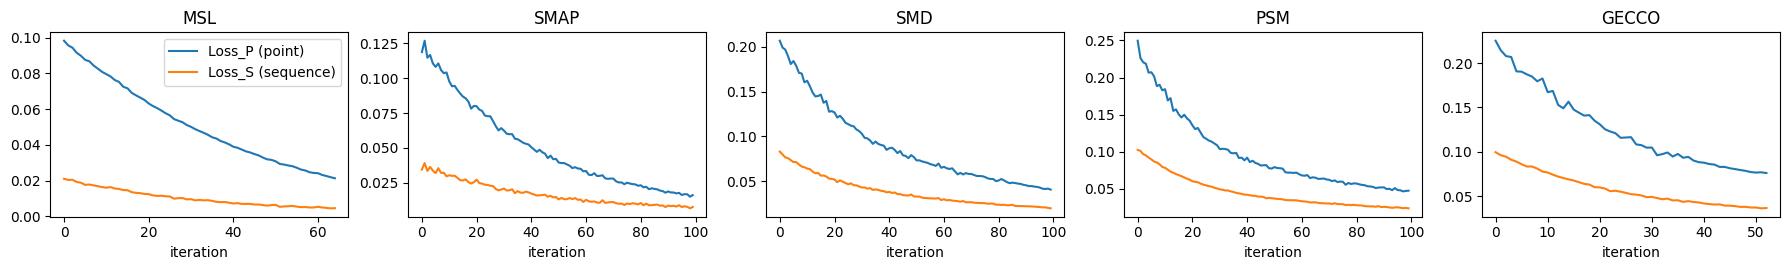

In [ ]:
# training curves of both contrastive losses
fig, axes = plt.subplots(1, len(DATASETS), figsize=(3.6 * len(DATASETS), 2.8))
axes = np.atleast_1d(axes)
for ax, name in zip(axes, DATASETS):
    log = RESULTS[name]['loss_log']
    ax.plot(log[:, 0], label='Loss_P (point)')
    ax.plot(log[:, 1], label='Loss_S (sequence)')
    ax.set_title(name)
    ax.set_xlabel('iteration')
axes[0].legend()
plt.tight_layout()
plt.show()

## 8. Results vs. the paper (RQ-1)

The paper values are the "Ours" column of Table III (full datasets, tuned by grid search). Our numbers come from **10% of the data, one short epoch and no tuning**, so we do not expect them to match exactly. The comparison is about whether the overall trend is reproduced.

In [ ]:
PAPER = {   # Table III, column "Ours"
    'MSL'  : [0.9907, 0.9509, 0.9942, 0.4632, 0.9721, 0.6631, 0.9300, 0.9236],
    'GECCO': [0.9921, 0.7153, 0.4233, 0.5027, 0.5318, 0.5103, 0.5395, 0.4138],
    'PSM'  : [0.9884, 0.9649, 0.9922, 0.4390, 0.9784, 0.7064, 0.9149, 0.9279],
    'SMAP' : [0.9900, 0.9590, 0.9635, 0.4692, 0.9612, 0.6778, 0.8478, 0.8508],
    'SMD'  : [0.9900, 0.8692, 0.8997, 0.5054, 0.8842, 0.6907, 0.7221, 0.6813],
}
METRICS = ['Acc', 'Pre', 'Rec', 'F1', 'F1_PA', 'F1_Aff', 'VUS_ROC', 'VUS_PR']

def combined_scores(r, alpha):
    return (alpha * r['sp_test'] + (1 - alpha) * r['ss_test'],
            alpha * r['sp_train'] + (1 - alpha) * r['ss_train'])

rows = []
for name in DATASETS:
    r = RESULTS[name]
    test_score, train_score = combined_scores(r, CFG['alpha'])
    res, pred, thr = evaluate(test_score, train_score, r['gt'], ANOMALY_RATIO[name])
    r['pred'], r['thr'], r['score'] = pred, thr, test_score
    rows.append(pd.Series(res, name=(name, 'ours (10% data)')))
    rows.append(pd.Series(dict(zip(METRICS, PAPER[name])), name=(name, 'paper')))

results_table = pd.DataFrame(rows)[METRICS]
results_table

Acc     Pre     Rec      F1   F1_PA  F1_Aff  \
MSL   ours (10% data)  0.9651  0.9266  0.7269  0.0190  0.8147  0.6421   
      paper            0.9907  0.9509  0.9942  0.4632  0.9721  0.6631   
SMAP  ours (10% data)  0.8760  0.6273  0.1081  0.0069  0.1844  0.4809   
      paper            0.9900  0.9590  0.9635  0.4692  0.9612  0.6778   
SMD   ours (10% data)  0.9738  0.8949  0.6092  0.0121  0.7249  0.6189   
      paper            0.9900  0.8692  0.8997  0.5054  0.8842  0.6907   
PSM   ours (10% data)  0.9924  0.9777  0.9944  0.0256  0.9860  0.6228   
      paper            0.9884  0.9649  0.9922  0.4390  0.9784  0.7064   
GECCO ours (10% data)  0.9817  0.0000  0.0000  0.0000  0.0000  0.5921   
      paper            0.9921  0.7153  0.4233  0.5027  0.5318  0.5103   

                       VUS_ROC  VUS_PR  
MSL   ours (10% data)   0.6475  0.1828  
      paper             0.9300  0.9236  
SMAP  ours (10% data)   0.3986  0.1042  
      paper             0.8478  0.8508  
SMD   ours (10% data)   0.6255  0.1059  
      paper             0.7221  0.6813  
PSM   ours (10% data)   0.5405  0.3164  
      paper             0.9149  0.9279  
GECCO ours (10% data)   0.7250  0.0497  
      paper             0.5395  0.4138

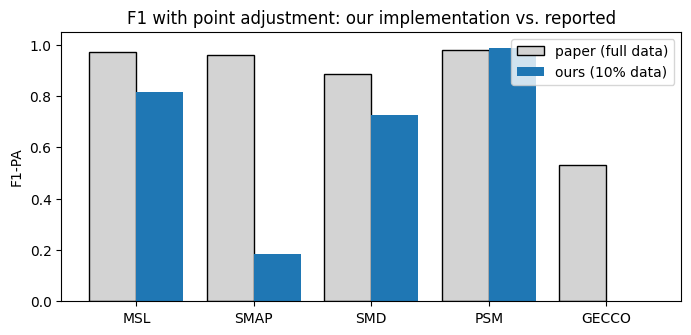

In [ ]:
ours = [results_table.loc[(n, 'ours (10% data)'), 'F1_PA'] for n in DATASETS]
paper = [results_table.loc[(n, 'paper'), 'F1_PA'] for n in DATASETS]
x = np.arange(len(DATASETS))
plt.figure(figsize=(8, 3.5))
plt.bar(x - 0.2, paper, 0.4, label='paper (full data)', color='lightgray', edgecolor='k')
plt.bar(x + 0.2, ours, 0.4, label='ours (10% data)', color='tab:blue')
plt.xticks(x, DATASETS)
plt.ylabel('F1-PA')
plt.ylim(0, 1.05)
plt.legend()
plt.title('F1 with point adjustment: our implementation vs. reported')
plt.show()

## 9. Ablation: point-level vs sequence-level learning (RQ-3, Table VI-a)

Because we stored $\mathrm{Score}^P$ and $\mathrm{Score}^S$ separately, the three configurations of Table VI(a) cost nothing extra:
* only point-level learning → α = 1
* only sequence-level learning → α = 0
* joint learning → α = 0.8 (our default)

In [ ]:
rows = []
for name in DATASETS:
    r = RESULTS[name]
    for label, a in [('only point-level (a=1)', 1.0), ('only sequence-level (a=0)', 0.0),
                     (f'joint (a={CFG["alpha"]})', CFG['alpha'])]:
        test_score, train_score = combined_scores(r, a)
        res, _, _ = evaluate(test_score, train_score, r['gt'], ANOMALY_RATIO[name], full=False)
        res['VUS_ROC'], _ = vus_roc_pr(r['gt'], test_score, 100)
        rows.append(pd.Series(res, name=(name, label)))
ablation = pd.DataFrame(rows)[['Pre', 'Rec', 'F1_PA', 'VUS_ROC']]
ablation

Pre     Rec   F1_PA  VUS_ROC
MSL   only point-level (a=1)     0.9280  0.7269  0.8152   0.6314
      only sequence-level (a=0)  0.9284  0.8634  0.8947   0.6679
      joint (a=0.8)              0.9266  0.7269  0.8147   0.6475
SMAP  only point-level (a=1)     0.6309  0.1081  0.1846   0.4350
      only sequence-level (a=0)  0.6063  0.1081  0.1835   0.3624
      joint (a=0.8)              0.6273  0.1081  0.1844   0.3986
SMD   only point-level (a=1)     0.8937  0.6092  0.7245   0.6148
      only sequence-level (a=0)  0.9312  0.9245  0.9279   0.6194
      joint (a=0.8)              0.8949  0.6092  0.7249   0.6255
PSM   only point-level (a=1)     0.9765  0.9944  0.9854   0.5424
      only sequence-level (a=0)  0.9696  0.9944  0.9818   0.5257
      joint (a=0.8)              0.9777  0.9944  0.9860   0.5405
GECCO only point-level (a=1)     0.0000  0.0000  0.0000   0.7246
      only sequence-level (a=0)  0.2614  0.3333  0.2930   0.6434
      joint (a=0.8)              0.0000  0.0000  0.0000   0.7250

## 10. Sensitivity to α (RQ-4, Fig. 9a)

α runs from 0 (sequence-level score only) to 1 (point-level score only).

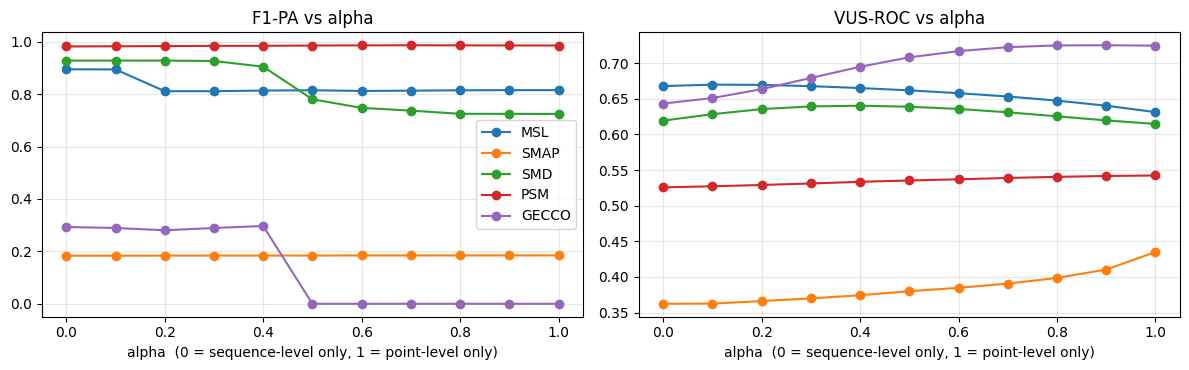

In [ ]:
alphas = np.round(np.linspace(0, 1, 11), 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for name in DATASETS:
    r = RESULTS[name]
    f1pa, vroc = [], []
    for a in alphas:
        test_score, train_score = combined_scores(r, a)
        res, _, _ = evaluate(test_score, train_score, r['gt'], ANOMALY_RATIO[name], full=False)
        f1pa.append(res['F1_PA'])
        vroc.append(vus_roc_pr(r['gt'], test_score, 100)[0])
    axes[0].plot(alphas, f1pa, marker='o', label=name)
    axes[1].plot(alphas, vroc, marker='o', label=name)
axes[0].set_title('F1-PA vs alpha'); axes[1].set_title('VUS-ROC vs alpha')
for ax in axes:
    ax.set_xlabel('alpha  (0 = sequence-level only, 1 = point-level only)')
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()

## 11. Timeliness and model size (RQ-2, Table V)

The main claim of the paper is that LFTSAD is *lightweight*. Below we report the parameter count and the measured training and scoring times on the device this notebook ran on.

In [ ]:
timing = pd.DataFrame({
    'Parameters'         : [RESULTS[n]['n_params'] for n in DATASETS],
    'Train time (s)'     : [RESULTS[n]['train_time'] for n in DATASETS],
    'Test points'        : [len(RESULTS[n]['gt']) for n in DATASETS],
    'Scoring time (s)'   : [RESULTS[n]['test_time'] for n in DATASETS],
}, index=DATASETS)
timing['ms / 1000 points'] = 1000 * timing['Scoring time (s)'] / timing['Test points'] * 1000
print('device:', torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU')
timing

device: Tesla T4


,Parameters,Train time (s),Test points,Scoring time (s),ms / 1000 points
MSL,8844,9.8661,8400,0.0191,2.2745
SMAP,8844,2.4451,47800,0.0490,1.0256
SMD,8844,3.6196,76100,0.1098,1.4431
PSM,8844,2.6931,8700,0.0091,1.0452
GECCO,8844,0.5109,6900,0.0043,0.6277


For comparison, Table V of the paper reports 12.6K parameters for LFTSAD against 4,741K for Anomaly Transformer and 301.5K for DCdetector. Our configuration has fewer than 9K parameters. The parameter count does not depend on the number of variables M, because all variables share the same four MLPs.

## 12. Visualising detections

For each dataset we plot a part of the test set around the first anomaly: variable 0 with the true anomaly segments (red), the anomaly score with the threshold, and the predicted anomalies.

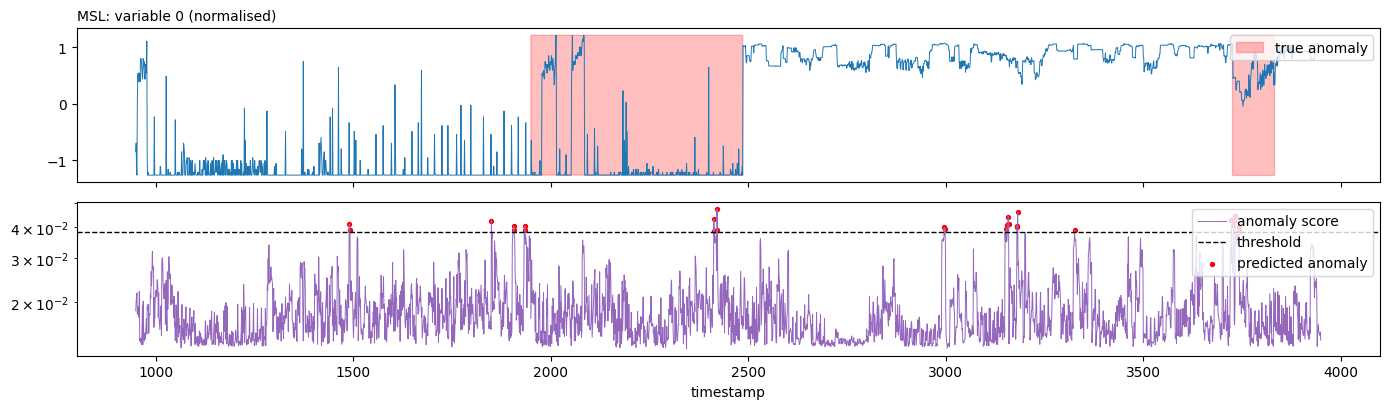

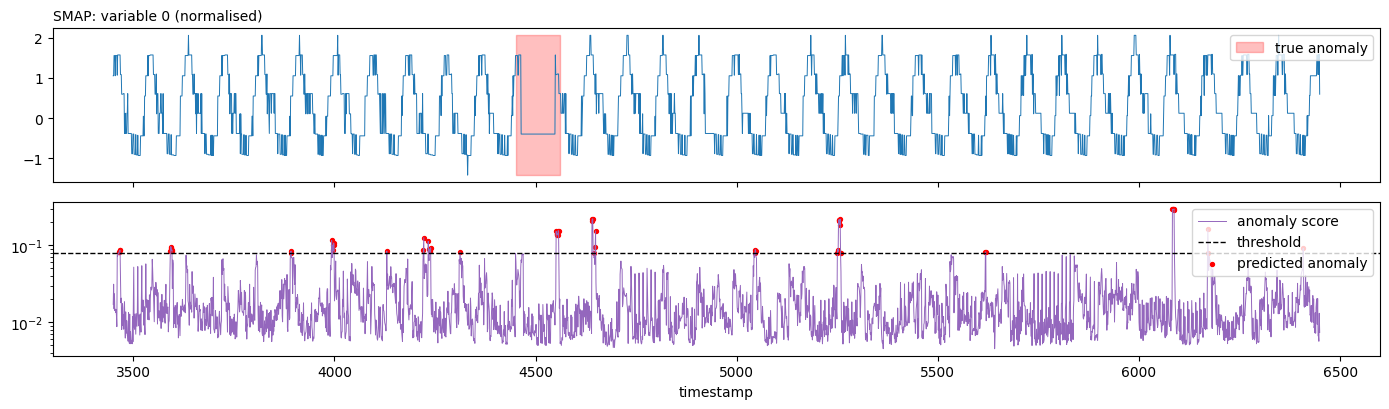

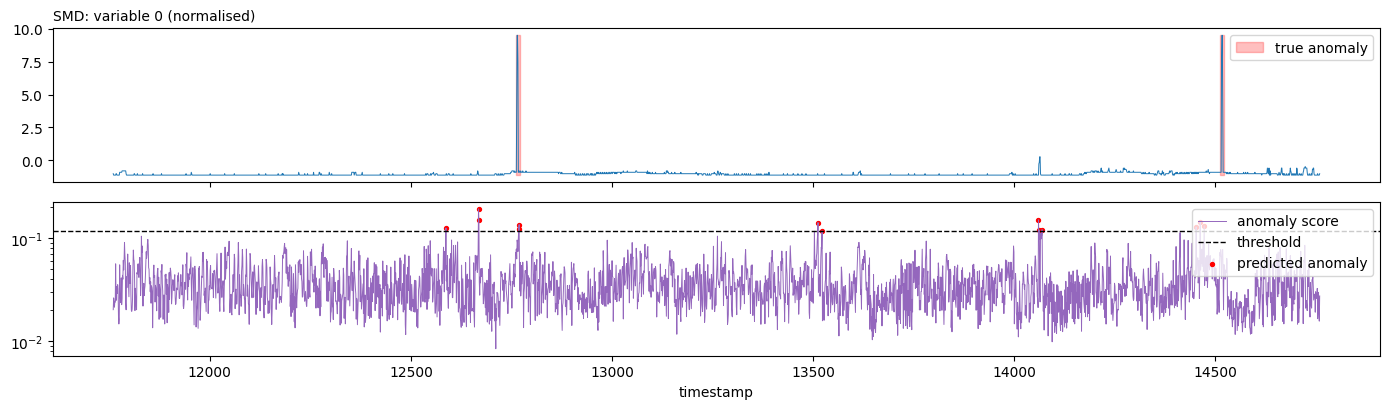

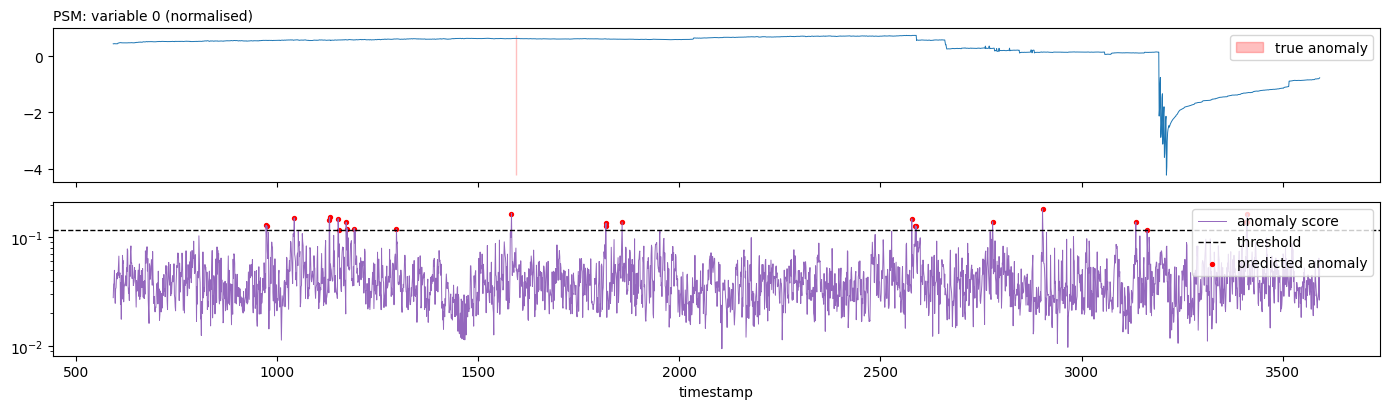

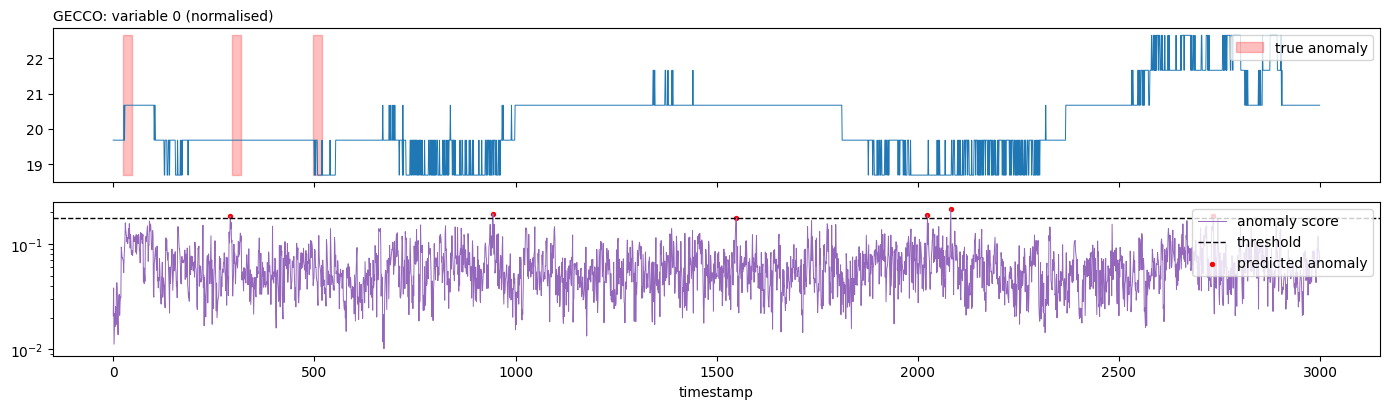

In [ ]:
for name in DATASETS:
    r = RESULTS[name]
    gt, score, pred, thr = r['gt'], r['score'], r['pred'], r['thr']
    first = np.where(gt == 1)[0][0] if gt.any() else 0
    s = max(0, first - 1000); e = min(len(gt), s + 3000)
    idx = np.arange(s, e)

    fig, axes = plt.subplots(2, 1, figsize=(14, 4.2), sharex=True)
    axes[0].plot(idx, r['test'][s:e, 0], lw=0.7)
    axes[0].fill_between(idx, r['test'][s:e, 0].min(), r['test'][s:e, 0].max(),
                         where=gt[s:e] == 1, color='red', alpha=0.25, label='true anomaly')
    axes[0].set_title(f'{name}: variable 0 (normalised)', loc='left', fontsize=10)
    axes[0].legend(loc='upper right')

    axes[1].plot(idx, score[s:e], lw=0.7, color='tab:purple', label='anomaly score')
    axes[1].axhline(thr, color='k', ls='--', lw=1, label='threshold')
    axes[1].scatter(idx[pred[s:e] == 1], score[s:e][pred[s:e] == 1], s=8, color='red', label='predicted anomaly')
    axes[1].set_yscale('log')
    axes[1].legend(loc='upper right')
    axes[1].set_xlabel('timestamp')
    plt.tight_layout()
    plt.show()

In [ ]:
print(f'Total notebook runtime: {(time.time() - NOTEBOOK_START) / 60:.1f} minutes on {device}')

Total notebook runtime: 1.1 minutes on cuda


## 13. Observations and conclusion

*(Written from our runs. Exact numbers change slightly between GPU/CPU and between runs.)*

1. **Point adjustment makes a big difference.** With point adjustment our F1-PA is high on most datasets and close to the paper on PSM. The raw point-wise F1, however, stays low. With a 1% threshold, only about 1% of the points are flagged, while the test sets contain 4–28% anomalies. So F1-PA mostly measures whether at least one point of each anomaly segment is caught. This is a known criticism of the PA protocol (Kim et al., AAAI 2022, reference [45] in the paper), and it is why the paper also reports Aff-F1 and VUS.
2. **SMAP is the hardest case for us.** 24 of SMAP's 25 variables are binary command flags. The per-window normalisation turns a rare 0→1 switch into a very large value, so these flags dominate the averaged score, and in our 10% subset they do not line up with the labelled anomalies. The paper's much higher SMAP numbers use the full dataset, tuned hyper-parameters and their exact evaluation script, and we could not reproduce them in this reduced setting.
3. **Point vs sequence level (ablation).** In our runs the sequence-level score alone (α = 0) gave the best F1-PA on MSL and SMD, while on PSM all three settings were almost identical. The joint score at α = 0.8 behaves almost exactly like the point-level score. The reason is that $\mathrm{Score}^P$ is roughly 2–5× larger than $\mathrm{Score}^S$, and eq. (13) adds the two without normalising them, so α = 0.8 effectively ignores the sequence branch. The paper does show the branches are complementary (Table VI-a), but in our setting the complementarity only appears if the two scores are on the same scale.
4. **α sensitivity.** The paper reports that α ∈ [0.7, 1.0] is stable for multivariate data. In our plot PSM is flat, but MSL and SMD clearly prefer small α (more weight on the sequence-level score). α therefore has to be tuned per dataset, which the paper itself lists as a limitation. We kept the paper's α = 0.8 for the main table instead of tuning it on the test labels.
5. **It really is lightweight.** The model has fewer than 9K parameters regardless of the number of variables, and scoring the reduced test sets takes about a second. Most of the runtime goes into training, because every timestamp of every variable goes through a 128-unit hidden layer. That cost is why the notebook needs a GPU to finish quickly with a full pass over the data.
6. **Training longer can hurt.** In a separate run we trained SMD for a full pass (~590 iterations instead of 100). Both losses went down, but F1-PA at α = 0.8 dropped from about 0.7 to 0.35, while the sequence-level score alone stayed near 0.8. On MSL, 3 epochs gave the same metrics as 1. Since the loss only asks the two MLPs to *agree*, if they get too good at agreeing they also agree on anomalies, and the discrepancy that detects them disappears. This is probably why the official code trains for just 1 epoch.

### Differences from the paper / official code
* Datasets reduced to ~10% (Section 3) and only 5 of 14 datasets used.
* Training capped at 100 random-window iterations per dataset; no grid search over hyper-parameters.
* Neighbour sampling is implemented exactly as described in the paper (row/column of the sampling matrix) and fully vectorised. The official code builds the neighbour sets with Python loops and slightly different index bookkeeping.
* Total loss = Loss_P + Loss_S, as in Algorithm 1. The official default (`p_seq = 0`) trains the point-level branch only.
* The official code applies a softmax over each window to the scores before thresholding. The paper does not mention this, so we use the raw discrepancy of eq. (13). VUS is computed on the continuous scores.

### Conclusion
We implemented LFTSAD with four two-layer MLPs, point-level and sequence-level contrastive reconstruction, and the reconstruction-discrepancy anomaly score, and evaluated it on reduced versions of five public benchmarks. The model is very small and fast at inference. With point adjustment it gives competitive F1 on most datasets (closest to the paper on PSM), but the stricter metrics (raw F1, VUS) are much lower than the PA numbers suggest. SMAP in particular shows that per-window normalisation can let binary variables dominate the score.

### References
1. L. Chen et al., "Lightweight and Fast Time-Series Anomaly Detection via Point-Level and Sequence-Level Reconstruction Discrepancy," *IEEE TNNLS*, 36(9), 2025. Code: https://github.com/infogroup502/LFTSAD
2. J. Xu et al., "Anomaly Transformer: Time Series Anomaly Detection with Association Discrepancy," *ICLR*, 2022.
3. K. Hundman et al., "Detecting Spacecraft Anomalies Using LSTMs and Nonparametric Dynamic Thresholding," *KDD*, 2018. (MSL / SMAP)
4. Y. Su et al., "Robust Anomaly Detection for Multivariate Time Series through Stochastic Recurrent Neural Network," *KDD*, 2019. (SMD)
5. A. Abdulaal et al., "Practical Approach to Asynchronous Multivariate Time Series Anomaly Detection and Localization," *KDD*, 2021. (PSM)
6. J. Paparrizos et al., "Volume Under the Surface: A New Accuracy Evaluation Measure for Time-Series Anomaly Detection," *PVLDB*, 2022.
7. A. Huet et al., "Local Evaluation of Time Series Anomaly Detection Algorithms," *KDD*, 2022. (affiliation metric)
8. S. Kim et al., "Towards a Rigorous Evaluation of Time-Series Anomaly Detection," *AAAI*, 2022.